# 01_Step1VsMonster: photometry of the step-1 stars against the Monster

For one visit of the run, read `single_visit_star` (end of stage 1), cross-match it with the Monster **using the same reference selection as `calibrateImage`** (ComCam columns, colour cut 0.4 <= g-r <= 2.0), and look at `psfFlux` magnitude minus Monster magnitude:
- versus magnitude (saturation, faint-end bias),
- versus Monster g-r colour (hint of a ComCam -> LSSTCam colour term, none is applied in the pipeline),
- per detector (sensor-to-sensor offsets),
- per Monster `source_flag`.

Helpers: `src/rubincc/monster.py`. Run with the `lsst` kernel at CC-IN2P3.

Caveats: positions are used at the Gaia epoch (no proper-motion correction); the flux unit of `psfFlux` (nJy expected) must be checked on the printed columns.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SRC = Path('../../src').resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from rubincc import monster as mon

NB_TAG = '01_Step1VsMonster'
DATA_DIR = Path(f'data_{NB_TAG}')
FIG_DIR = Path(f'figs_{NB_TAG}')
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.labelsize'] = 'x-large'
plt.rcParams['axes.titlesize'] = 'x-large'
plt.rcParams['xtick.labelsize'] = 'x-large'
plt.rcParams['ytick.labelsize'] = 'x-large'


def savefig(fig, name):
    # every figure is saved as PDF and PNG
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'{NB_TAG}_{name}.{ext}', bbox_inches='tight', dpi=150)

In [2]:
REPO = 'main'
USER = os.getenv('USER')

# stage-1 output collection of the run to analyse
RUN_COLLECTION = f'u/{USER}/LSSTCam/runcosmos01_20261026_tract9813patch50_RunCosmosDemo/stage1'

# the Monster is the same whatever the run collection: read it from the refcat collection
MONSTER_DATASET = mon.DEFAULT_MONSTER_DATASET
MONSTER_COLLECTIONS = 'refcats/DM-49042/the_monster_20250219'
REF = 'monster_ComCam'  # the pipeline maps every LSSTCam band to the ComCam columns

VISIT = None            # None = first visit found
MAX_SEP_ARCSEC = 1.0
MAG_RANGE = (16.0, 20.0)  # Monster magnitude range used for the summary statistics

## 1. Visits available in the run

In [3]:
run_butler = mon.get_butler(REPO, collections=RUN_COLLECTION)
refs = run_butler.query_datasets('single_visit_star', limit=2000)
visits = sorted({ref.dataId['visit'] for ref in refs})
print(len(visits), 'visits with single_visit_star (query limited to 2000 datasets)')
print(visits[:20])

if VISIT is None:
    VISIT = visits[0]
print('VISIT =', VISIT)

2000 visits with single_visit_star (query limited to 2000 datasets)
[2025041700536, 2025041700537, 2025041700538, 2025041700539, 2025041700540, 2025041700541, 2025041700542, 2025041700543, 2025041700544, 2025041700546, 2025041700547, 2025041700548, 2025041700549, 2025041700550, 2025041700551, 2025041700553, 2025041700554, 2025041700555, 2025041700557, 2025041700558]
VISIT = 2025041700536


In [4]:
src = run_butler.get('single_visit_star', visit=VISIT, instrument='LSSTCam')
src_df = mon.as_dataframe(src)
print(src_df.shape)
print(list(src_df.columns))

needed = ['ra', 'dec', 'psfFlux', 'psfFluxErr', 'band', 'detector']
missing = [c for c in needed if c not in src_df.columns]
assert not missing, f'columns not found in single_visit_star: {missing}'

BAND = src_df['band'].iloc[0]
print('band =', BAND, '| bands in table:', src_df['band'].unique())
print(src_df[['ra', 'dec', 'psfFlux', 'psfFluxErr']].describe().T)

(4687, 157)
['coord_ra', 'coord_dec', 'parentSourceId', 'x', 'y', 'xErr', 'yErr', 'ra', 'dec', 'raErr', 'decErr', 'ra_dec_Cov', 'calibFlux', 'calibFluxErr', 'ap03Flux', 'ap03FluxErr', 'ap03Flux_flag', 'ap06Flux', 'ap06FluxErr', 'ap06Flux_flag', 'ap09Flux', 'ap09FluxErr', 'ap09Flux_flag', 'ap12Flux', 'ap12FluxErr', 'ap12Flux_flag', 'ap17Flux', 'ap17FluxErr', 'ap17Flux_flag', 'ap25Flux', 'ap25FluxErr', 'ap25Flux_flag', 'ap35Flux', 'ap35FluxErr', 'ap35Flux_flag', 'ap50Flux', 'ap50FluxErr', 'ap50Flux_flag', 'ap70Flux', 'ap70FluxErr', 'ap70Flux_flag', 'sky', 'skyErr', 'psfFlux', 'psfFluxErr', 'ixx', 'iyy', 'ixy', 'ixxPSF', 'iyyPSF', 'ixyPSF', 'ixxDebiasedPSF', 'iyyDebiasedPSF', 'ixyDebiasedPSF', 'gaussianFlux', 'gaussianFluxErr', 'extendedness', 'sizeExtendedness', 'blendedness_abs', 'blendedness_flag', 'blendedness_flag_noCentroid', 'blendedness_flag_noShape', 'apFlux_12_0_flag', 'apFlux_12_0_flag_apertureTruncated', 'apFlux_12_0_flag_sincCoeffsTruncated', 'apFlux_12_0_instFlux', 'apFlux_1

## 2. Monster over the footprint of the visit, with the pipeline reference selection

In [5]:
from astropy.coordinates import SkyCoord
import astropy.units as u

ra_c = float(src_df['ra'].median())
dec_c = float(src_df['dec'].median())
pts = SkyCoord(src_df['ra'].to_numpy() * u.deg, src_df['dec'].to_numpy() * u.deg)
radius = float(SkyCoord(ra_c * u.deg, dec_c * u.deg).separation(pts).deg.max()) + 0.05
print(f'footprint centre = ({ra_c:.4f}, {dec_c:.4f}) deg, cone radius = {radius:.3f} deg')

mon_df = mon.load_monster_cone(run_butler, ra_c, dec_c, radius, dataset=MONSTER_DATASET,
                               collections=MONSTER_COLLECTIONS, verbose=False)
print('Monster sources in the cone:', len(mon_df))

footprint centre = (150.9878, 2.3233) deg, cone radius = 0.385 deg
Monster sources in the cone: 1782


In [6]:
flux_col = f'{REF}_{BAND}_flux'
flag_col = f'{REF}_{BAND}_source_flag'

mon_df['gr_ref'] = (mon.flux_njy_to_abmag(mon_df[f'{REF}_g_flux'])
                    - mon.flux_njy_to_abmag(mon_df[f'{REF}_r_flux']))

# calibrateImage selection: colour cut on the ComCam g-r; we also need a valid flux in this band
sel = (np.isfinite(mon_df['gr_ref']) & (mon_df['gr_ref'] >= 0.4) & (mon_df['gr_ref'] <= 2.0)
       & (mon_df[flux_col] > 0))
ref = mon_df[sel].reset_index(drop=True)
print(f'reference stars kept: {len(ref)} / {len(mon_df)}')

idx, sep, ok = mon.crossmatch(src_df['ra'], src_df['dec'], ref['ra_deg'], ref['dec_deg'],
                              max_sep_arcsec=MAX_SEP_ARCSEC)
print(f'matched {int(ok.sum())} / {len(ok)} step-1 stars within {MAX_SEP_ARCSEC} arcsec')

match = src_df.loc[ok, ['detector', 'ra', 'dec', 'psfFlux', 'psfFluxErr']].reset_index(drop=True)
match['sep_arcsec'] = sep[ok]
match['m_src'] = mon.flux_njy_to_abmag(match['psfFlux'])
match['m_ref'] = mon.flux_njy_to_abmag(ref[flux_col].to_numpy()[idx[ok]])
match['gr_ref'] = ref['gr_ref'].to_numpy()[idx[ok]]
match['flag'] = ref[flag_col].to_numpy()[idx[ok]]
# extra columns used in the colour/magnitude and Gaia cross-checks below
gi_all = mon.flux_njy_to_abmag(ref[f'{REF}_g_flux']) - mon.flux_njy_to_abmag(ref[f'{REF}_i_flux'])
G_all = mon.flux_njy_to_abmag(ref['phot_g_mean_flux'])
r_all = mon.flux_njy_to_abmag(ref[f'{REF}_r_flux'])
match['gi_ref'] = gi_all[idx[ok]]
match['gaia_outlier'] = ((G_all - r_all) > 1.0)[idx[ok]]
match['dmag'] = match['m_src'] - match['m_ref']
match = match[np.isfinite(match['dmag'])].reset_index(drop=True)
match.to_csv(DATA_DIR / f'{NB_TAG}_visit{VISIT}_{BAND}_match.csv', index=False)
match.head()

reference stars kept: 1181 / 1782
matched 409 / 4687 step-1 stars within 1.0 arcsec


,detector,ra,dec,psfFlux,psfFluxErr,sep_arcsec,m_src,m_ref,gr_ref,flag,dmag
0,139,150.673417,2.421502,31932.328119,281.313091,0.099998,20.139424,20.141088,0.660993,2,-0.001665
1,139,150.677853,2.399227,39114.976453,291.934908,0.113453,19.919142,19.890069,1.303389,2,0.029074
2,139,150.683920,2.376521,27509.211339,276.344206,0.051114,20.301305,20.286973,1.332154,2,0.014332
3,139,150.675854,2.435201,162231.289957,426.154759,0.048790,18.374663,18.366651,1.122448,2,0.008012
4,139,150.683583,2.409388,392281.884103,608.148529,0.290163,17.416004,17.407378,0.857321,2,0.008627


## 3. psfFlux - Monster magnitude

 m_ref_lo  n  median_dmag  sigma_mad
     15.5 11        0.004      0.009
     16.0 20       -0.002      0.007
     16.5 27       -0.001      0.006
     17.0 37        0.002      0.005
     17.5 42        0.005      0.009
     18.0 56        0.010      0.016
     18.5 62        0.012      0.022
     19.0 58        0.012      0.013
     19.5 64        0.010      0.013
     20.0 25        0.010      0.012
     20.5  7       -0.006      0.010


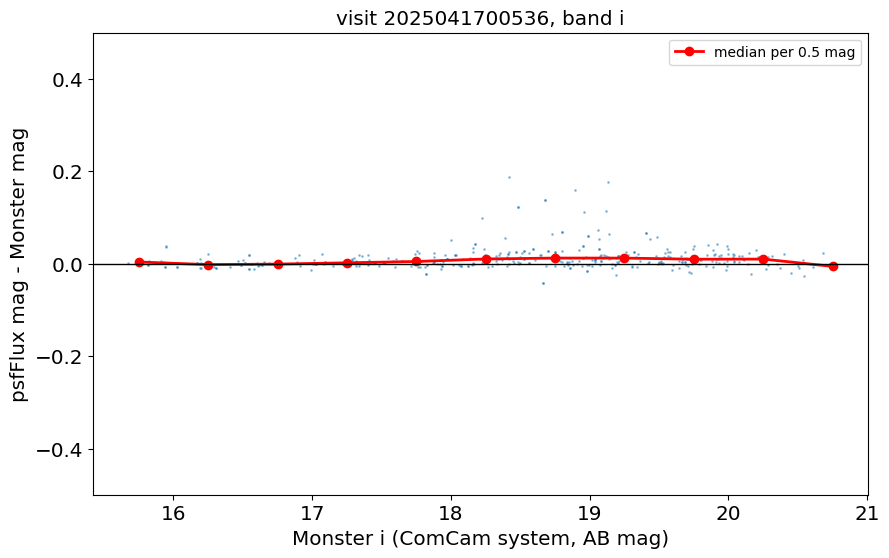

In [7]:
def robust_stats(x):
    x = np.asarray(x, dtype=float)
    med = np.median(x)
    return med, 1.4826 * np.median(np.abs(x - med))


bins = np.arange(12.0, 22.5, 0.5)
rows = []
for lo, hi in zip(bins[:-1], bins[1:]):
    s = match[(match['m_ref'] >= lo) & (match['m_ref'] < hi)]
    if len(s) >= 5:
        med, sig = robust_stats(s['dmag'])
        rows.append({'m_ref_lo': lo, 'n': len(s), 'median_dmag': med, 'sigma_mad': sig})
by_mag = pd.DataFrame(rows)
by_mag.to_csv(DATA_DIR / f'{NB_TAG}_visit{VISIT}_{BAND}_by_mag.csv', index=False)
print(by_mag.round(3).to_string(index=False))

fig, ax = plt.subplots()
ax.plot(match['m_ref'], match['dmag'], '.', ms=2, alpha=0.4)
ax.plot(by_mag['m_ref_lo'] + 0.25, by_mag['median_dmag'], 'r-o', lw=2, label='median per 0.5 mag')
ax.axhline(0, color='k', lw=1)
ax.set_ylim(-0.5, 0.5)
ax.set_xlabel(f'Monster {BAND} (ComCam system, AB mag)')
ax.set_ylabel('psfFlux mag - Monster mag')
ax.set_title(f'visit {VISIT}, band {BAND}')
ax.legend()
savefig(fig, f'visit{VISIT}_dmag_vs_mag')

16.0 <= m_ref <= 20.0: N=366, median dmag = 0.0060, sigma_MAD = 0.0130
          median  count
detector               
139       0.0108    132
141       0.0043    128
142       0.0041    106


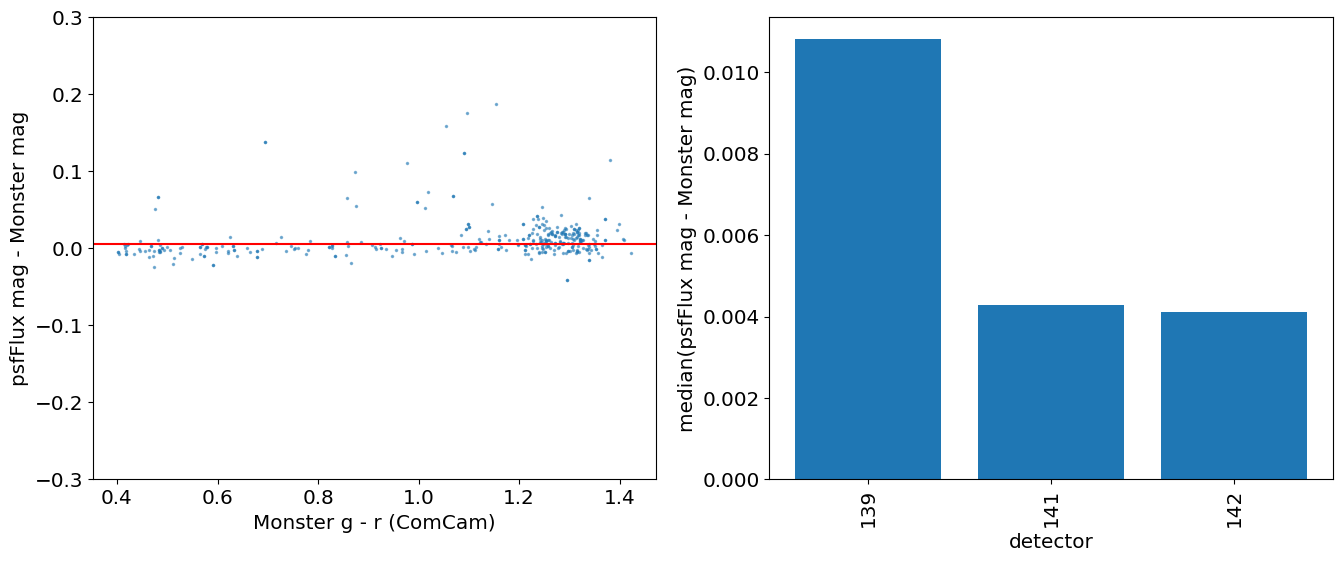

In [8]:
core = match[(match['m_ref'] >= MAG_RANGE[0]) & (match['m_ref'] <= MAG_RANGE[1])]
med, sig = robust_stats(core['dmag'])
print(f'{MAG_RANGE[0]} <= m_ref <= {MAG_RANGE[1]}: N={len(core)}, median dmag = {med:.4f}, sigma_MAD = {sig:.4f}')

# colour dependence: a slope here would hint at a ComCam -> LSSTCam colour term
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(core['gr_ref'], core['dmag'], '.', ms=3, alpha=0.5)
axes[0].axhline(med, color='r')
axes[0].set_ylim(-0.3, 0.3)
axes[0].set_xlabel('Monster g - r (ComCam)')
axes[0].set_ylabel('psfFlux mag - Monster mag')

# per-detector median offsets
per_det = core.groupby('detector')['dmag'].agg(['median', 'count'])
per_det = per_det[per_det['count'] >= 10]
axes[1].bar(per_det.index.astype(str), per_det['median'])
axes[1].set_xlabel('detector')
axes[1].set_ylabel('median(psfFlux mag - Monster mag)')
axes[1].tick_params(axis='x', rotation=90)
savefig(fig, f'visit{VISIT}_colour_detector')
print(per_det.round(4))

In [9]:
# offsets per Monster source_flag (the flag identifies the catalogue the Monster flux comes from)
rows = []
for flag, s in core.groupby('flag'):
    if len(s) >= 5:
        med, sig = robust_stats(s['dmag'])
        rows.append({'flag': int(flag), 'n': len(s), 'median_dmag': med, 'sigma_mad': sig})
pd.DataFrame(rows).round(4)

,flag,n,median_dmag,sigma_mad
0,2,315,0.0056,0.0110
1,4,6,-0.0105,0.0011
2,8,45,0.0277,0.0553


In [ ]:
# is the dmag trend with colour real, or only the magnitude trend (red stars are also the faint ones)?
core = match[(match['m_ref'] >= MAG_RANGE[0]) & (match['m_ref'] <= MAG_RANGE[1])]
slices = ((MAG_RANGE[0], 18.5), (18.5, MAG_RANGE[1]))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, (lo, hi) in zip(axes, slices):
    s = core[(core['m_ref'] >= lo) & (core['m_ref'] < hi)]
    ax.plot(s['gi_ref'], s['dmag'], '.', ms=4, alpha=0.5)
    ax.axhline(0, color='k', lw=1)
    ax.set_ylim(-0.1, 0.1)
    ax.set_title(f'{lo} <= Monster {BAND} < {hi} (N={len(s)})')
    ax.set_xlabel('Monster g - i (ComCam)')
axes[0].set_ylabel('psfFlux mag - Monster mag')
savefig(fig, f'visit{VISIT}_dmag_vs_gi_by_mag')

rows = []
for lo, hi in slices:
    for clo, chi in ((0.4, 1.0), (1.0, 1.6), (1.6, 2.2), (2.2, 3.5)):
        s = core[(core['m_ref'] >= lo) & (core['m_ref'] < hi) & (core['gi_ref'] >= clo) & (core['gi_ref'] < chi)]
        if len(s) >= 5:
            med, sig = robust_stats(s['dmag'])
            rows.append({'mag': f'{lo}-{hi}', 'g-i': f'{clo}-{chi}', 'n': len(s), 'median_dmag': med, 'sigma_mad': sig})
pd.DataFrame(rows).round(4)

In [ ]:
# do the flag-8 / Gaia-inconsistent Monster stars drive the residuals?
core = match[(match['m_ref'] >= MAG_RANGE[0]) & (match['m_ref'] <= MAG_RANGE[1])]
print('Gaia-inconsistent (G - r > 1) among the matched stars:', int(core['gaia_outlier'].sum()), 'of', len(core))
print(pd.crosstab(core['flag'], core['gaia_outlier']))
for name, s in (('all', core),
                ('without flag 8', core[core['flag'] != 8]),
                ('without Gaia-inconsistent', core[~core['gaia_outlier']])):
    med, sig = robust_stats(s['dmag'])
    print(f'{name:28s} N={len(s):4d} median={med:.4f} sigma_MAD={sig:.4f}')
print('separation (arcsec), 50/90/99 percentiles:', np.percentile(match['sep_arcsec'], [50, 90, 99]).round(3))